In [ ]:
import pandas as pd
import numpy as np

sheet_id = "1B_zrNj6vaC8-Cg6ypu9Tz9uRLIPtzBBLL9yRLtVyiAY"
gid = "1073279846"  # ID của sheet/tab

url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"

df = pd.read_csv(url)

print("Kích thước dữ liệu:", df.shape)
print("\nDanh sách cột:")
print(df.columns.tolist())

display(df.head())

Kích thước dữ liệu: (1767, 18)

Danh sách cột:
['product_id', 'title', 'authors', 'original_price', 'current_price', 'quantity', 'category', 'n_review', 'avg_rating', 'pages', 'manufacturer', 'cover_link', 'discount', 'discount_percent', 'revenue', 'price_segment', 'rating_group', 'page_segment']


,product_id,title,authors,original_price,current_price,quantity,category,n_review,avg_rating,pages,manufacturer,cover_link,discount,discount_percent,revenue,price_segment,rating_group,page_segment
0,74021317,Cây Cam Ngọt Của Tôi,José Mauro De Vasconcelos,4.56,2.73,53075,Tiểu Thuyết,11481,5.0,244,Nhà Xuất Bản Hội Nhà Văn,https://salt.tadacdn.com/ts/product/5e/18/24/2...,0.4,40.13,"144894,75",Dưới $5,Xuất sắc (4.5 - 5.0),Sách trung bình (200-500 trang)
1,184466860,Hành Tinh Của Một Kẻ Nghĩ Nhiều,Nguyễn Đoàn Minh Thư,3.63,2.53,7929,Others,780,4.8,184,Nhà Xuất Bản Thế Giới,https://salt.tadacdn.com/ts/product/d7/99/24/1...,0.3,30.30,"20060,37",Dưới $5,Xuất sắc (4.5 - 5.0),Sách mỏng (<200 trang)
2,73787185,Những Tù Nhân Của Địa Lý,Tim Marshall,8.86,5.32,17896,Lĩnh Vực Khác,3623,4.8,430,Nhà Xuất Bản Hội Nhà Văn,https://salt.tadacdn.com/ts/product/8d/96/9e/c...,0.4,39.95,"95206,72",Từ $5 - $10,Xuất sắc (4.5 - 5.0),Sách trung bình (200-500 trang)
3,52789367,Nhà Giả Kim (Tái Bản 2020),Paulo Coelho,3.33,2.00,24668,Tác Phẩm Kinh Điển,5131,5.0,228,Nhà Xuất Bản Hà Nội,https://salt.tadacdn.com/ts/product/45/3b/fc/a...,0.4,39.94,49336,Dưới $5,Xuất sắc (4.5 - 5.0),Sách trung bình (200-500 trang)
4,147920903,Một Thoáng Ta Rực Rỡ Ở Nhân Gian,Unknown,5.70,3.42,10000,Tiểu Thuyết,1636,4.8,304,Nhà Xuất Bản Hội Nhà Văn,https://salt.tadacdn.com/ts/product/2f/b5/4e/a...,0.4,40.00,34200,Dưới $5,Xuất sắc (4.5 - 5.0),Sách trung bình (200-500 trang)


In [ ]:
# Quy tắc tạo nhãn is_bestseller
if "is_bestseller" not in df.columns:
    df["is_bestseller"] = (
        df["quantity"] >= 500
    ).astype(int)

print("Phân bố nhãn:")
print(df["is_bestseller"].value_counts())

print("\nTỷ lệ từng lớp:")
print(df["is_bestseller"].value_counts(normalize=True).round(3))

Phân bố nhãn:
is_bestseller
1    947
0    820
Name: count, dtype: int64

Tỷ lệ từng lớp:
is_bestseller
1    0.536
0    0.464
Name: proportion, dtype: float64


In [ ]:

# Chọn Features và chia Train/Test

from sklearn.model_selection import train_test_split

numeric_candidates = [
    "current_price",
    "original_price",
    "avg_rating",
    "n_review",
    "pages",
    "discount_percent"
]

categorical_candidates = [
    "category",
    "manufacturer",
    "price_segment",
    "rating_group",
    "page_segment"
]

numeric_features = [
    c for c in numeric_candidates if c in df.columns
]

categorical_features = [
    c for c in categorical_candidates if c in df.columns
]

feature_cols = numeric_features + categorical_features

# Giữ lại các dòng có nhãn hợp lệ
df = df.dropna(subset=["is_bestseller"]).copy()
df["is_bestseller"] = df["is_bestseller"].astype(int)

if not set(df["is_bestseller"].unique()).issubset({0, 1}):
    raise ValueError("is_bestseller phải chỉ gồm 0 và 1.")

X = df[feature_cols].copy()
y = df["is_bestseller"].copy()

# Làm sạch giá trị số bất thường và thiếu
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    X[col] = X[col].replace([np.inf, -np.inf], np.nan)

# Chuẩn hóa giá trị thiếu của các biến phân loại
for col in categorical_features:
    X[col] = X[col].fillna("Không rõ").astype(str)

print("Các biến đầu vào:", feature_cols)
print("\nPhân bố nhãn:")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTrain:", X_train.shape)
print("Test:", X_test.shape)

#stratify=y giúp giữ tỷ lệ hai lớp gần với tỷ lệ trong dữ liệu ban đầu. Các bước điền giá trị thiếu, mã hóa và chuẩn hóa tiếp theo sẽ được đặt trong pipeline để tránh rò rỉ thông tin từ tập test.

Các biến đầu vào: ['current_price', 'original_price', 'avg_rating', 'n_review', 'pages', 'discount_percent', 'category', 'manufacturer', 'price_segment', 'rating_group', 'page_segment']

Phân bố nhãn:
is_bestseller
1    947
0    820
Name: count, dtype: int64

Train: (1413, 11)
Test: (354, 11)


In [ ]:

# dùng Logistic Regression làm baseline và Random Forest để so sánh


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Tiền xử lý cho Logistic Regression
numeric_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_lr = ColumnTransformer([
    ("num", numeric_lr, numeric_features),
    ("cat", categorical_lr, categorical_features)
])

model_lr = Pipeline([
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Tiền xử lý cho Random Forest
numeric_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_rf = ColumnTransformer([
    ("num", numeric_rf, numeric_features),
    ("cat", categorical_rf, categorical_features)
])

model_rf = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Huấn luyện
model_lr.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

print("Đã huấn luyện xong hai mô hình.")

Đã huấn luyện xong hai mô hình.


In [ ]:

# đánh giá hiệu suất

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models = {
    "Logistic Regression": model_lr,
    "Random Forest": model_rf
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

    print(f"\n===== {name} =====")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Not Bestseller", "Bestseller"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

results_df = pd.DataFrame(results)
display(results_df.round(3))


===== Logistic Regression =====
                precision    recall  f1-score   support

Not Bestseller       0.86      0.95      0.90       164
    Bestseller       0.95      0.86      0.90       190

      accuracy                           0.90       354
     macro avg       0.90      0.90      0.90       354
  weighted avg       0.91      0.90      0.90       354

Confusion Matrix:
[[155   9]
 [ 26 164]]

===== Random Forest =====
                precision    recall  f1-score   support

Not Bestseller       0.90      0.93      0.92       164
    Bestseller       0.94      0.92      0.93       190

      accuracy                           0.92       354
     macro avg       0.92      0.92      0.92       354
  weighted avg       0.92      0.92      0.92       354

Confusion Matrix:
[[152  12]
 [ 16 174]]


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.901,0.948,0.863,0.904
1,Random Forest,0.921,0.935,0.916,0.926


Kết quả cho thấy Random Forest có hiệu suất tổng thể tốt hơn Logistic Regression. Cụ thể, Random Forest đạt Accuracy 92.1% và F1-score của lớp Bestseller khoảng 92.6%, cao hơn mức 90.1% và 90.4% tương ứng của Logistic Regression.

Mặc dù Logistic Regression có Precision cao hơn (94.8% so với 93.5%), Random Forest đạt Recall cao hơn (91.6% so với 86.3%). Điều này cho thấy Random Forest phát hiện được tỷ lệ sách Bestseller thực tế cao hơn, phù hợp với mục tiêu hạn chế bỏ sót các cuốn sách có tiềm năng bán chạy

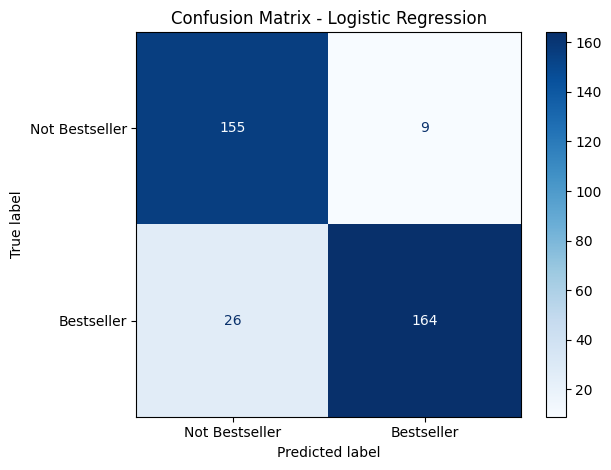

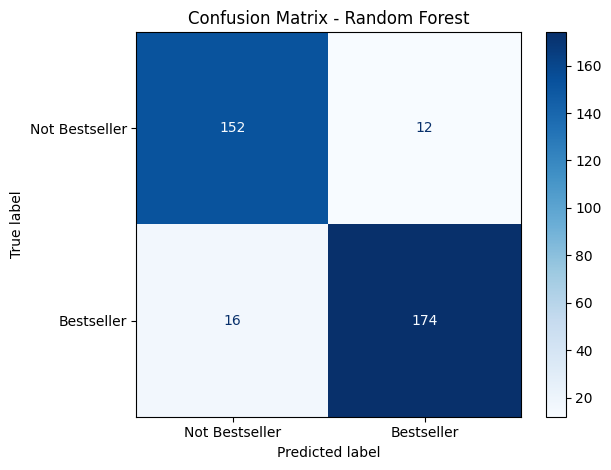

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        labels=[0, 1],
        display_labels=["Not Bestseller", "Bestseller"],
        cmap="Blues"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [ ]:

# True Negative: Dự đoán không bestseller và thực tế cũng không bestseller.

# False Positive: Dự đoán bestseller nhưng thực tế không phải.

# False Negative: Bỏ sót sách bestseller.

# True Positive: Dự đoán đúng sách bestseller.


Logistic Regression:

True Negative: 155 cuốn sách không phải Bestseller được dự đoán chính xác.

False Positive: 9 cuốn sách không phải Bestseller bị dự đoán nhầm thành Bestseller.

False Negative: 26 cuốn sách Bestseller bị bỏ sót.

True Positive: 164 cuốn sách Bestseller được dự đoán chính xác.


Random Forest:

True Negative: 152 cuốn sách không phải Bestseller được dự đoán chính xác.

False Positive: 12 cuốn sách không phải Bestseller bị dự đoán nhầm thành Bestseller.

False Negative: 16 cuốn sách Bestseller bị bỏ sót.

True Positive: 174 cuốn sách Bestseller được dự đoán chính xác.

So với Logistic Regression, Random Forest nhận diện đúng thêm 10 cuốn sách Bestseller và giảm số trường hợp bỏ sót từ 26 xuống 16. Đổi lại, số trường hợp dự đoán nhầm sách không Bestseller thành Bestseller tăng từ 9 lên 12.

Vì vậy, nếu ưu tiên tìm ra nhiều sách có tiềm năng bán chạy để tiếp tục đánh giá hoặc cân nhắc hoạt động marketing, Random Forest là lựa chọn phù hợp hơn trong hai mô hình đã thử nghiệm

,Feature,Importance
3,num__n_review,0.604165
5,num__discount_percent,0.071993
2,num__avg_rating,0.044860
1,num__original_price,0.042450
0,num__current_price,0.040752
73,cat__manufacturer_Unknown,0.035427
4,num__pages,0.030833
81,cat__rating_group_Xuất sắc (4.5 - 5.0),0.008194
78,cat__rating_group_Chưa có đánh giá,0.007205
84,cat__page_segment_Sách trung bình (200-500 trang),0.006243


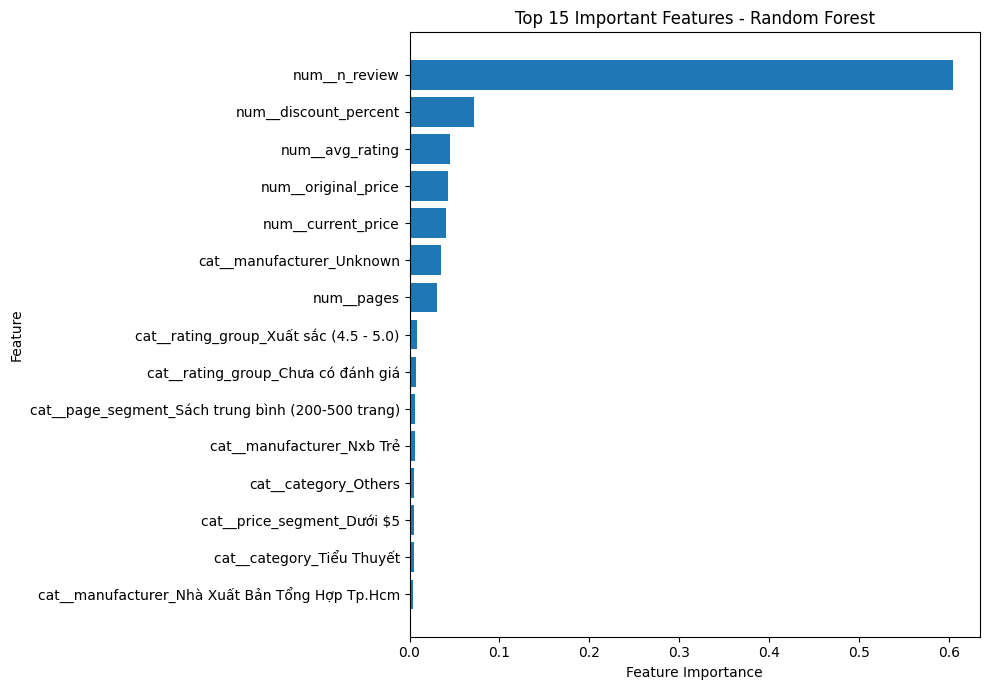

In [ ]:

# Phân tích Feature Importance
# Với Random Forest, ta lấy độ quan trọng của các biến sau khi One-Hot Encoding, rồi vẽ biểu đồ Top 15


# Lấy tên các đặc trưng sau tiền xử lý
preprocessor = model_rf.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()
importances = model_rf.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

# Biểu đồ Top 15
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features - Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
#Số lượt đánh giá (n_review) là đặc trưng nổi bật nhất, chiếm khoảng 60.42% tổng Feature Importance của Random Forest.
#Kết quả này cho thấy số lượt đánh giá đóng vai trò quan trọng trong cách mô hình phân loại sách Bestseller và Not Bestseller trên bộ dữ liệu hiện tại.